# 딥러닝 ① FOCUS ON IMAGE + SEQUENCE

## 1. 합성곱 신경망 (CNN)  
  
### 0. 픽셀과 채널  
  
1. 픽셀의 개념  
- 픽셀은 이미지 데이터를 구성하는 가장 기본적인 단위
- 하나의 픽셀은 이미지의 특정 위치에 해당하는 색상 또는 밝기 정보를 포함
  
**이미지 데이터에서 픽셀의 활용**  
- 이미지 크기: 흑백 이미지의 크기는 일반적으로 이미지 데이터의 기본 단위인 2차원 배열 = (세로 픽셀 수 × 가로 픽셀 수)로 표현
  
**픽셀 값의 표현 방법**  
- 흑백 이미지: 하나의 픽셀 값으로 밝기를 표현하며, 일반적으로 0부터 255까지의 값을 사용. 0은 검은색, 255는 흰색을 의미하고, 그 사이의 값은 밝기에 따라 다양한 회색으로 표현.
- 컬러 이미지: 하나의 픽셀을 빨강, 초록, 파랑 세 가지 색상 값으로 표현. 각 채널은 0부터 255까지의 값을 가지며, 세 값의 조합으로 하나의 색상이 만들어짐  
  
2. 채널  
- 이미지의 색상 정보를 구성하는 각각의 데이터 층
- 하나의 이미지에서 색상이나 밝기 정보를 구분하여 저장하는 단위
  
3. 색공간  
- 이미지를 구성하는 색상을 숫자로 표현하는 방법이나 체계
- 이미지의 색상 정보를 어떤 기준으로 표현하느냐에 따라 다양한 색공간이 존재
- 대표적인 색공간
    - 그레이 스케일: 색상 구분 없이 밝기 정보만으로 이미지 표현
    - RGB: 빨강, 초록, 파랑의 조합으로 색을 표현
    - HSV: 색상, 채도, 명도를 기준으로 색 표현
  
**그레이 스케일**  
- 이미지의 색상 정보 없이 픽셀의 밝기만을 이용해 표현하는 방식
- 각 픽셀은 하나의 채널 값으로 표현되며, 일반적으로 0~255 범위의 명도 값을 사용
- 흑백 이미지이므로 채널 수가 1임을 고려하면 (28 × 28 × 1)의 크기를 가지는 3차원 텐서로 표현 가능. 다만 NumPy에서는 채널 차원을 생략하여 일반적으로 (28 × 28)의 2차원 배열로 저장하기도 함
  
**RGB**  
- 빨강, 초록, 파랑의 조합으로 색을 표현
- 하나의 픽셀은 세 가지 색깔, 삼원색의 조합으로 이루어짐
- 세 가지 채널의 값이 합쳐져 최종적인 하나의 색상을 만들어내는 원리이므로, 채널 값은 3으로 표현됨
- 높이가 28, 너비가 28인 컬러 이미지의 텐서는 (28 × 28 × 3)의 크기를 가지는 3차원 텐서

### 1. CNN의 개념  
  
1. 이미지 인식 방법 차이  
**컴퓨터가 이미지를 인식하는 방법**  
- 이미지를 작은 픽셀 단위로 구분
- 각 픽셀에 저장된 색상과 밝기 등의 숫자 정보를 처리
  
> 픽셀 정보를 그냥 학습하면?  
  
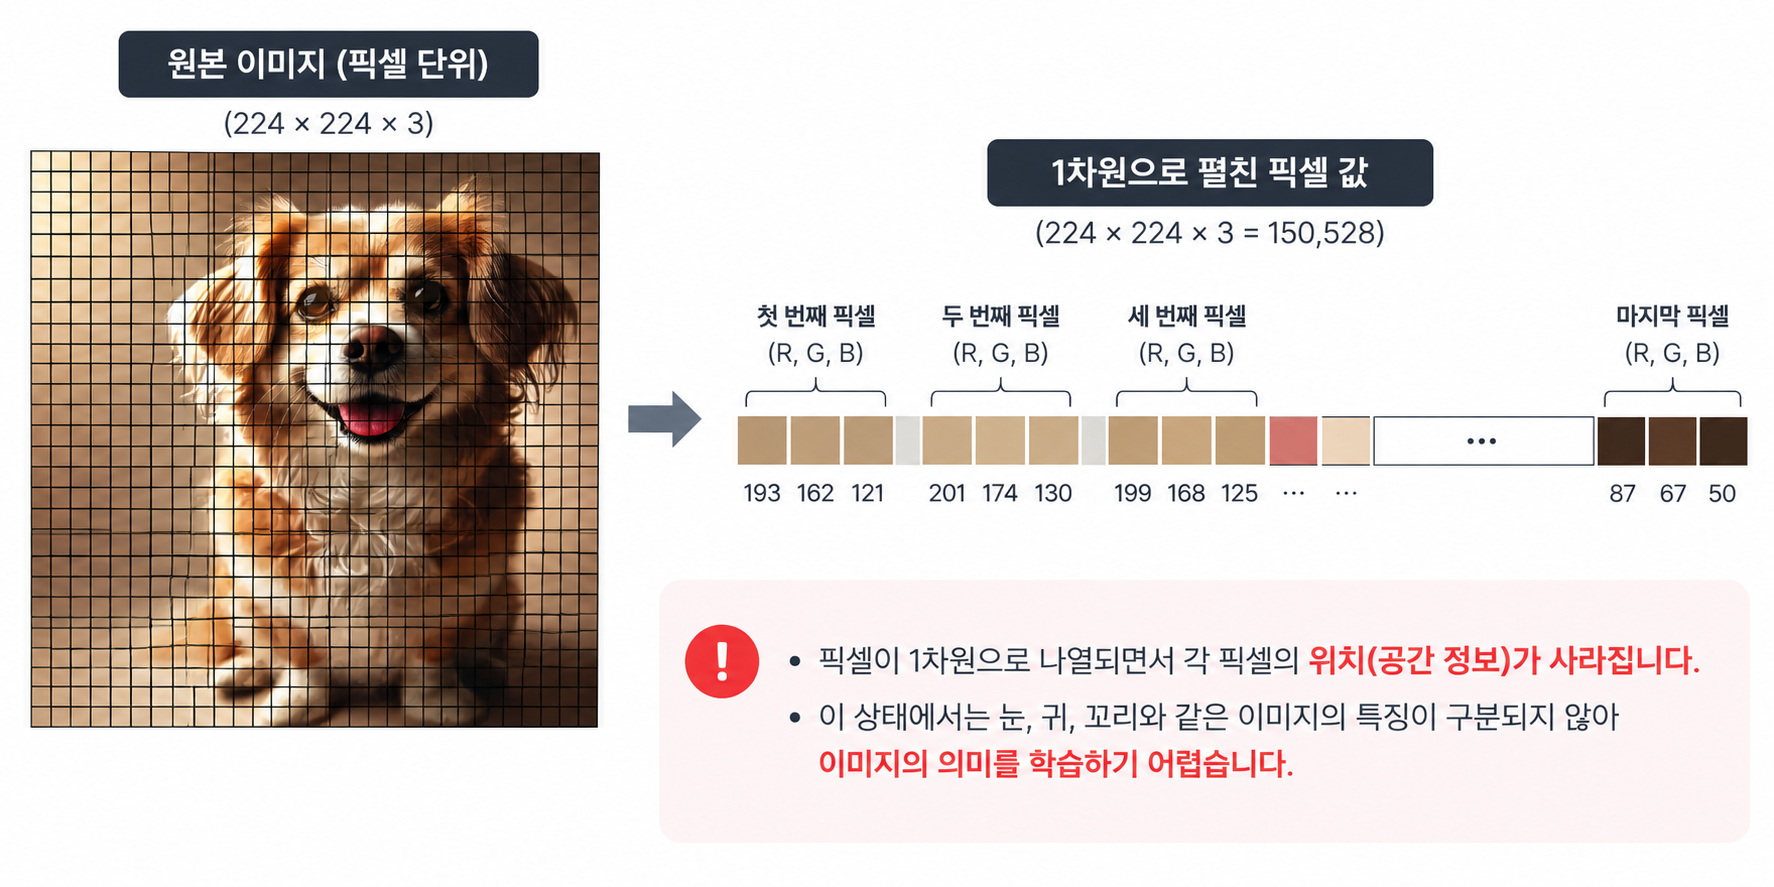  
  
- 원래 이미지가 가진 2차원 공간 구조 활용 불가
- 픽셀의 배열 순서가 무작위로 바뀌는 것은 아니나, 서로 가까이 있는 픽셀들이 갖는 관계에 대한 정보가 모델에 직접 반영되지 않음  
  
2. MLP와 CNN의 구조 비교  
  
MLP = FC Layer + ... + FC Layer  
  
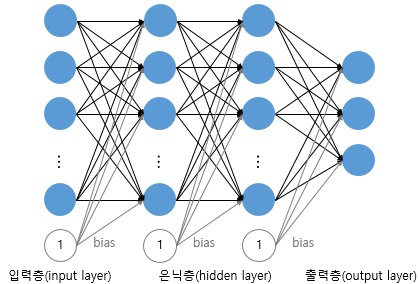  
  
- 입력된 데이터를 FC Layer에 전달하여 학습
- 2차원 이미지를 1차원 배열로 펼친 뒤 사용  
    
CNN = (Conv + Pool) + ... + Flatten + FC Layer + ... + FC Layer**  
  
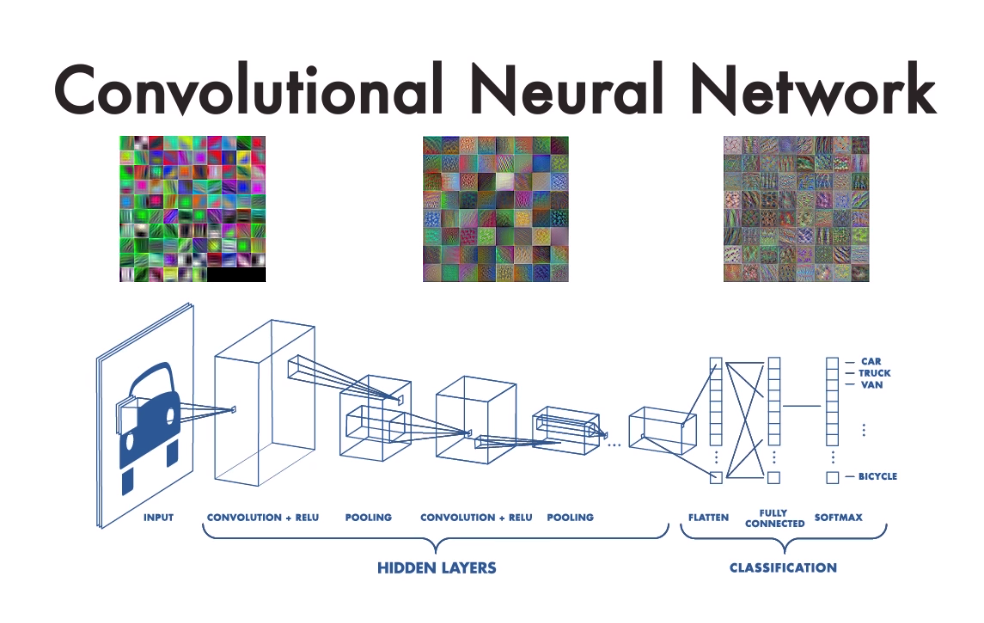  
  
- 이미지의 공간적 특징 유지
- Conv와 Pool 반복하여 이미지의 특징 추출
  
> 가장 큰 차이점?  
- CNN이 FC Layer 적용 전에 Conv와 Pool을 이용해 이미지의 특징을 학습하는 과정이 추가됨  
  
3. CNN  
  
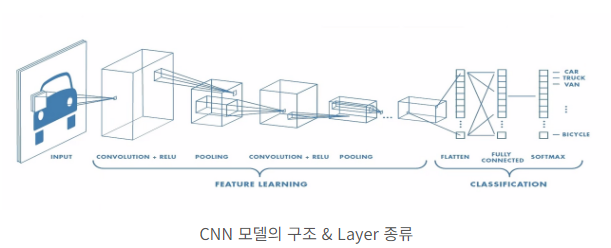  
  
- 특징 추출  
    - Convolution Layer: 필터를 이미지 위에서 이동시키며 모서리, 질감, 형태 등 이미지의 다양한 특징을 추출함  
    - Pooling Layer: 추출된 특징 맵의 크기를 줄이고 중요한 특징을 유지하여 연산량을 감소
- Flatten
    - 여러 차원으로 이루어진 특징 맵을 FC Layer에 입력할 수 있도록 1차원 배열로 변환
- 분류
    - Fully Connected Layer: 추출된 특징들을 종합하여 이미지가 어떤 클래스에 속하는지 최종적으로 분류

### 2. 이미지 처리에 CNN을 사용하는 이유  
  
1. 이미지 데이터의 구조  
  
**흑백 이미지의 구조**  
  
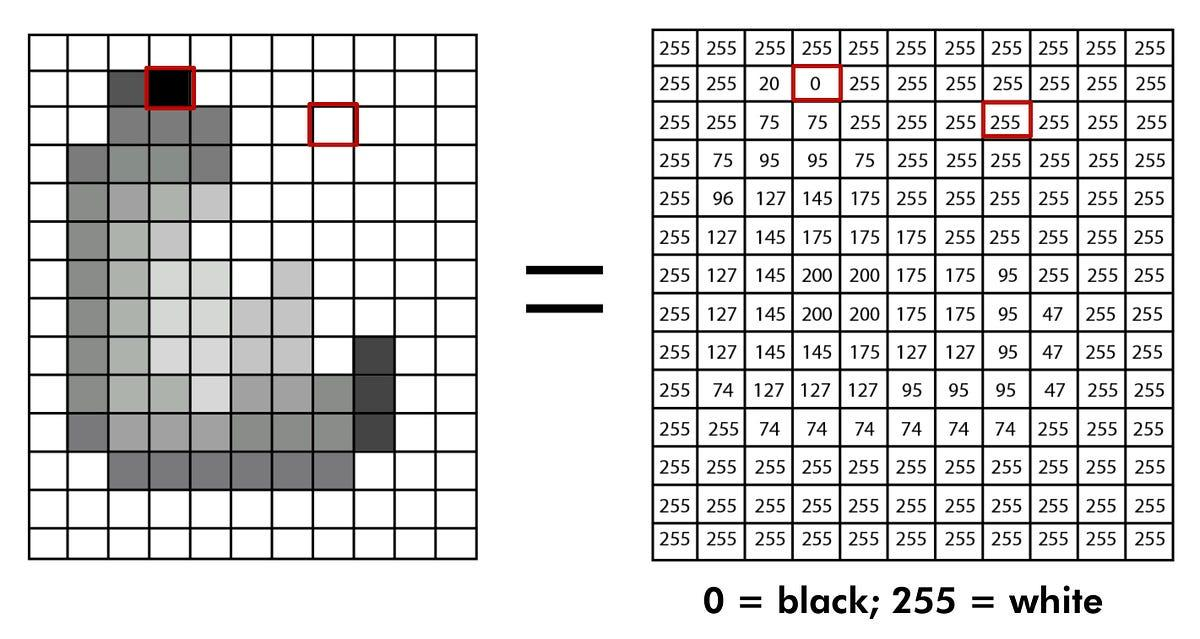  
  
- 흑백 이미지는 각 픽셀에 하나의 밝기 값을 저장하는 방식
- 픽셀 값은 일반적으로 0~255 범위로 표현하며, 0은 검은색, 255는 흰색을 의미
- 흑백 이미지는 각 픽셀에 하나의 값(0~255)만 존재하므로 H × W 형태의 2차원 배열로 표현 가능
  
**컬러 이미지의 구조**  
  
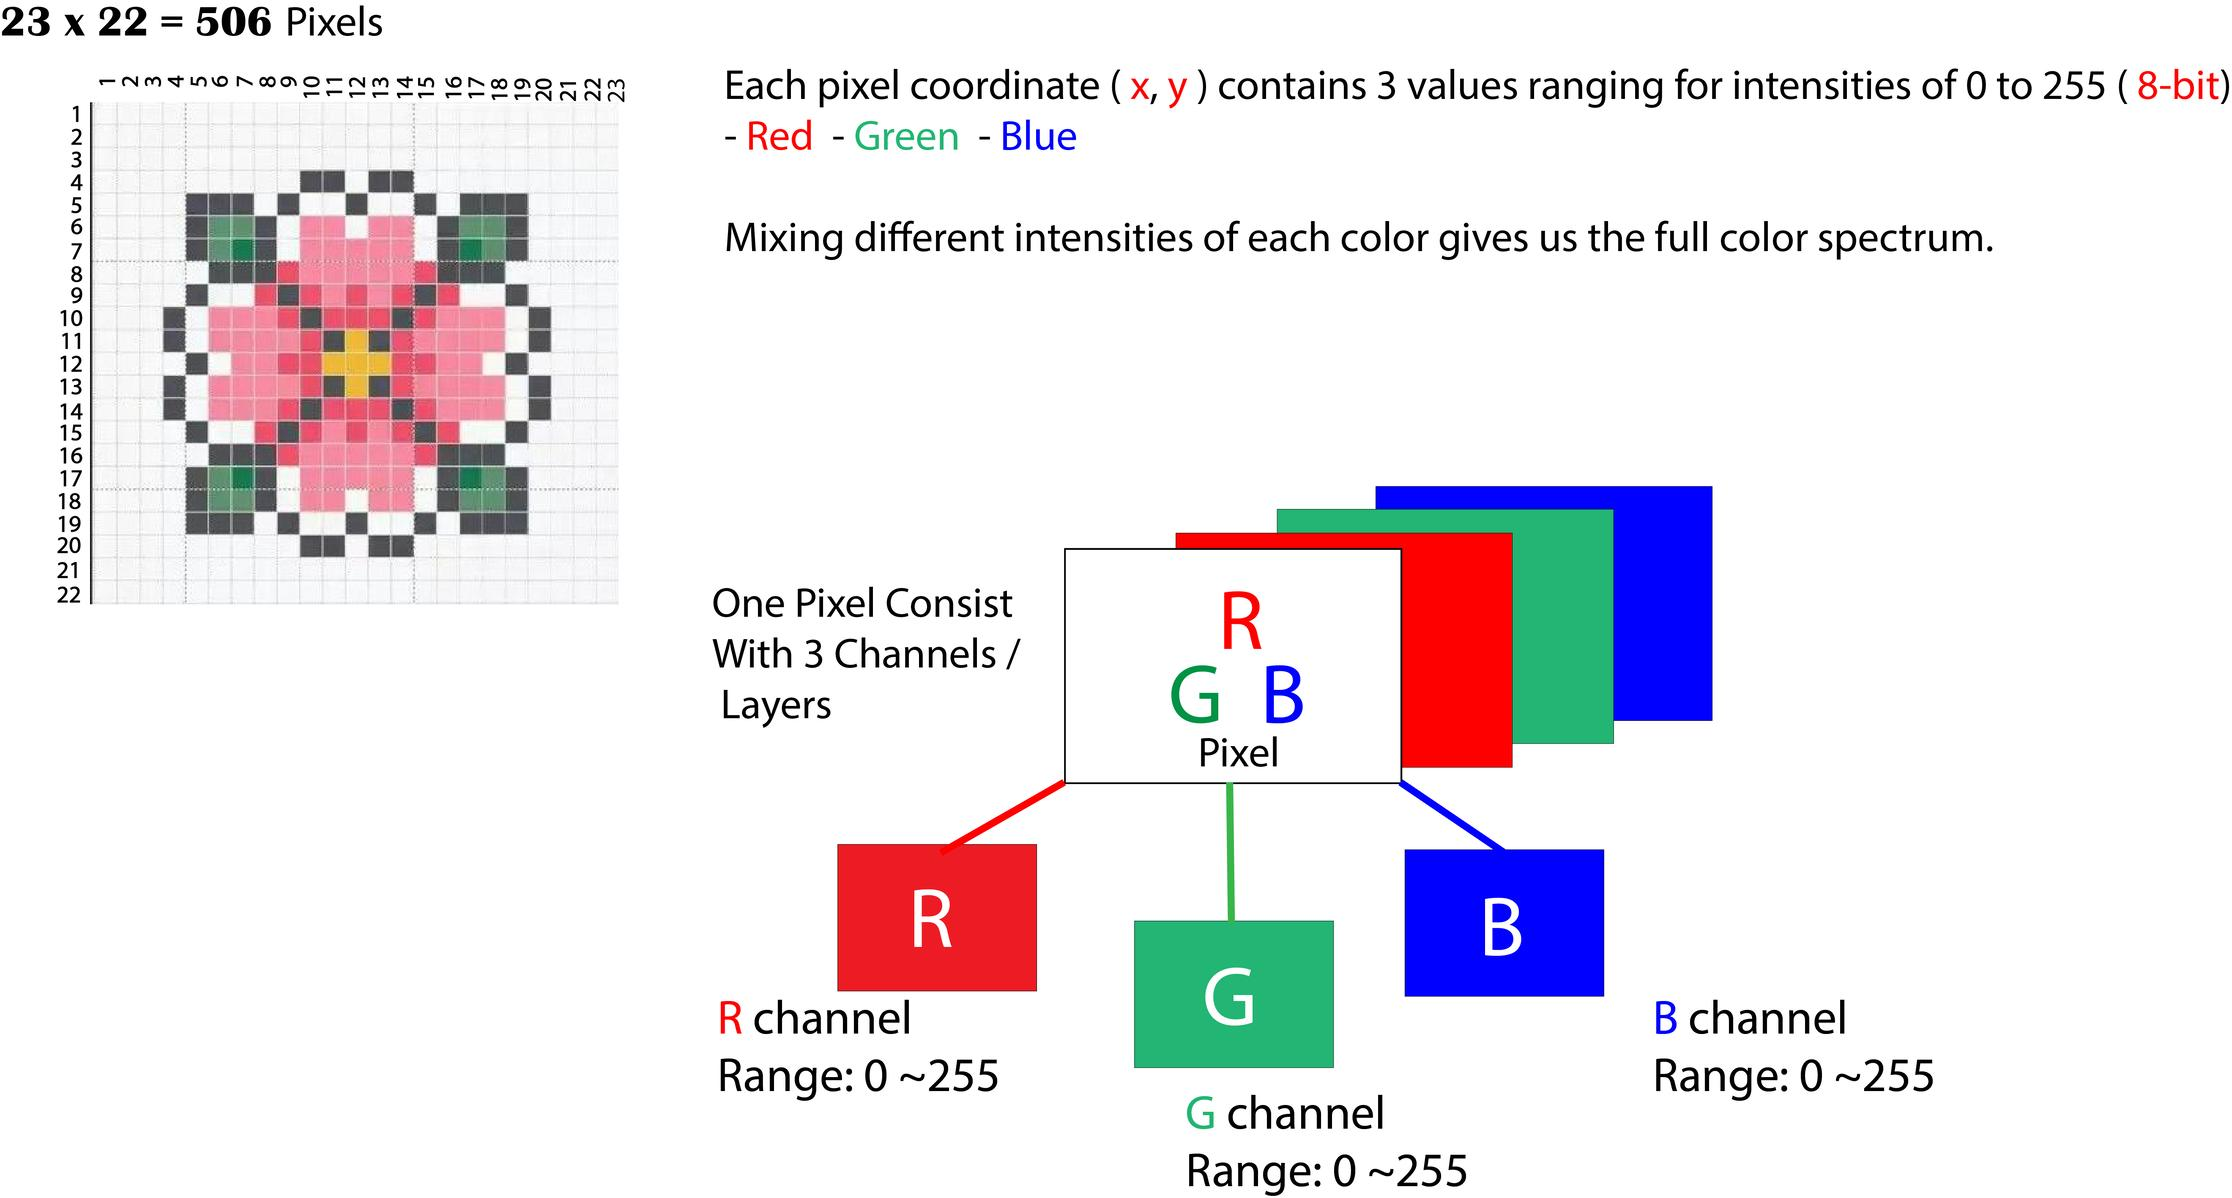  
  
- RGB 이미지는 하나의 픽셀이 Red(빨강), Green(초록), Blue(파랑) 세 가지 색상 값으로 구성
- 각 채널은 일반적으로 0~255 범위의 값을 가지며, 세 값의 조합으로 하나의 색상이 만들어짐
- 컬러 이미지는 각 픽셀마다 3개의 색상 값이 존재하므로 (H × W × 3) 형태의 3차원 배열로 표현
  
**MNIST**  
- 대표적인 이미지 데이터셋
- 손글씨 숫자 이미지로 구성
- 0~9 숫자를 담은 (28 × 28) 크기의 흑백 이미지 데이터셋
  
**이미지 구조를 유지하는 모델이 필요한 이유**  
- 일반적인 정형 데이터는 나이, 소득, 키와 같이 각 열에 독립적인 의미를 가진 값들이 나열된 형태
- 이미지는 픽셀들이 가로와 세로 방향으로 연결되어 있으며, 주변 픽셀 간의 관계와 위치 정보가 중요
- 이미지 데이터를 단순히 숫자 목록으로 처리하기보다는, 픽셀 간의 공간적 관계와 이미지의 구조를 유지하면서 특징을 학습할 수 있는 모델이 필요하며, 그 대표적인 모델이 CNN
  
2. MLP의 한계
  
**위치, 크기, 회전 등 변화에 취약**  
- MLP
    - 학습 데이터에서 보지 못한 위치나 형태의 변화가 발생하면 기존의 숫자로 인식하지 못할 가능성이 높아져 성능이 크게 저하
- CNN
    - Convolution으로 특징 추출: 모델이 '특징'을 학습
    - Pooling으로 차원 축소: 위치/크기 변화에 덜 민감
    - 어떤 영역에 특정한 특징이 존재하는가를 보므로 위치에 무관
    
2. 파라미터 폭발  
  
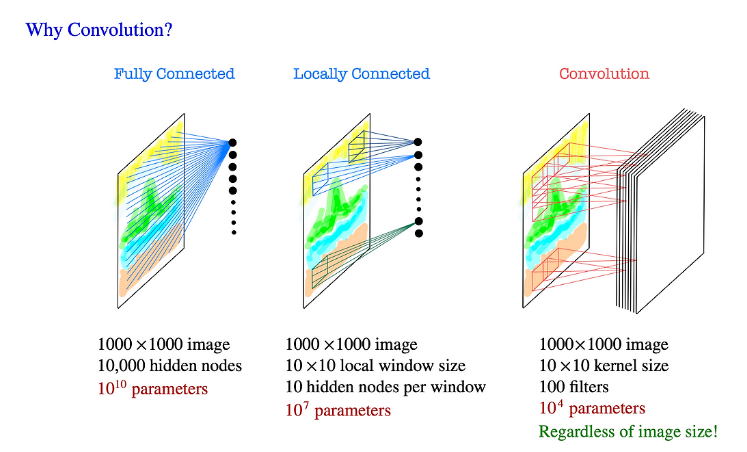  
  
- MLP
    - 완전연결 구조로 인한 파라마터 급증
    - 가중치 수가 이미지 픽셀의 개수만큼 생성
- CNN
    - 부분연결 구조하여 파라미터 수 크게 증가하지 않음

3. 공간 정보 손실
- MLP
    - 2차원 이상의 이미지 데이터 -> 1차원으로 펼침. flatten
    - 위 과정에서 이미지의 공간정보 많이 손실
- CNN
    - 다차원 이미지를 입력받은 그대로 다차원 구조를 유지한 상태로 처리
    - 이미지의 특징을 어느 정도 추출한 후 flatten

### 3. 합성곱(Convolution)과 풀링(Pooling)  
  

1. Convolution Layer
> 전체 이미지를 일정 크기의 필터로 훑으면서 이미지의 특징을 학습  
  
(1) 필터가 이미지 위를 슬라이딩  
    - 작은 크기의 필터를 입력 이미지의 왼쪽 위에 배치하고 이후 일정 한 간격만큼 이동하면서 이미지의 각 영역 확인
(2) 각 위치에서 요소별 곱셈 후 합계 계산  
(3) 결과를 Feature Map에 저장  
    - Feature Map: C필터가 특정 특징에 반응할 수록 해당 위치의 Feature Map 커짐
  

2. Padding  
> Convolution 연산 수행 전, 입력 이미지의 가장자리에 추가적인 픽셀 삽입  
  
- 이미지 크기를 유지하면서 가장자리 특징까지 반영
  

3. Stride  
> 특징을 얼마나 세밀하게 추출할지, 연산 효율을 어떻게 조절할지 결정하는 요소    
  
- Stride=1: 한 칸씩 이동 (세밀한 특징 추출)
- Stride=2: 두 칸씩 이동 (빠른 처리, 크기 축소)
- stride 커질수록 feature map의 크기 작아짐
  

4. Pooling  
> 이미지의 작은 위치 변화에 대한 민감도를 낮춰 모델이 특징을 더 안정적으로 인식할 수 있도록 도와줌    
  
- Max Pooling: 지정된 영역 안 최댓값 선택
- Average Pooling: 평균값 선택
- 장점
    - 차원을 축소시켜 계산량 감소
    - 위치 변화에 대한 강건성
    - 불필요한 정보를 제거해 과적합 방지
    - 노이즈 영향 완화
- 단점
    - 정보 소실 위험
    - 정확한 위치 정보 감소

### 4. 대표적인 CNN 아키텍처  
  
    
1. AlexNet (2012)  
> 대규모 이미지 데이터를 활용해 이미지의 특징을 직접 학습하고 분류하는 딥러닝의 가능성을 보여준 CNN 모델  
  
  
- 5개의 Convolutional Layer + 3개의 Fully Connected Layer -> 총 8층 구조
- Convolution Layer에서 이미지 특징 추출 -> Fully Connected Layer에서 이미지의 클래스를 분류
- 중간에 ReLU 활성화 함수와 Max Pooling 적용
  
2. VGGNet (2014)  
> 네트워크의 깊이를 눌리면 이미지 인식 성능이 향상될 수 있다는 점을 보여준 모델  
  
- Conv+Pool(max)을 여러번 반복 
- Filter 크기가 3*3으로 고정 -> 여러번 적용해 다양한 특징을 학습

  
3. ResNet (2015)  
> 잔차 연결 구조를 도입 -> 깊은 신경망을 효과적으로 학습  
    
- 여러 개의 Conv Layer 사이에 Skip Connection 추가
- Skip Connection: 입력 정보를 중간 계층을 거치지 않고 뒤쪽 계층으로 직접 전달하는 연결 방식

## 2. 이미지 딥러닝 응용

### 1. 이미지 분류  
  
- 이미지 분류 모델: 이미지를 수치 데이터로 인식 -> 사전 정의된 클래스 중 하나로 분류
    - AlexNet, VGG, ResNet, ViT
    - ViT: 이미지를 작은 패치(Patch) 단위로 나누고, 이를 Transformer에 입력하여 이미지의 특징을 학습하는 모델, Attentio을 활용해 이미지 패치 간 관계 학습
  
- CNN 확장 가능성
    - YOLO: 이미지 안에 존재하는 여러 객체를 찾아내는 모델 중 하나
  
### 2. 객체 탐지  
  
- 객체 탐지: 이미지 안에 있는 개별 객체의 종류와 위치를 함께 예측
- Bouncing Box: 이미지에서 객체가 위치한 영역을 둘러싸는 사각형
  
[모델 적용 방식]  
- CNN을 통해 Feature map 얻고, 그 위데 두 가지 head 올림
    - Classification Head: 객체의 클래스 예측
    - Regression Head: 객체의 위치 (x, y, width, height) 좌표 예측
- 대표 모델: YOLO, Faster R-CNN, SSD 등
  
### 3. 이미지 캡셔닝  
  
- 이미지 캡셔닝: 이미지의 내용을 자연어 문장으로 표현하는 작업
    - 이미지 특징 추출하는 CNN + 문장 생성하는 RNN
- 객체들 간 관계를 파악하고 자연어 형태로 표현
- 단계
(1) CNN을 이용하여 특징 추출  
(2) Attention Network를 이용하여 단어 생성  
    - Attention Network 통과하여 중요한 부분에 가중치 둠 -> 단어 추출
    - 가중치 높은 부분을 이용해 사진을 한 문장으로 설명
(3) RNN 이용하여 문장 생성  
    - 가중치 바탕으로 추출해낸 이미지 주요 단어들을 RNN을 통해 조합 -> 문장 완성

## 3. 과거를 기억하는 신경망: RNN  
  
### 1. 순차 데이터  
  
**순차 데이터**: 순서에 의미가 있으며, 순서가 달라질 경우 정보가 달라지는 데이터  
   
- 순차 데이터 세부 분류
    - 순서: 시간적 순차 데이터 / 비시간적 순차 데이터
    - 자료형: 수치형 / 범주형
  
- 기존 정형 데이터 vs 순차 데이터  
    - 정형 데이터 특징: 순서 바꿔도 의미 변화 없음
    - 순차 데이터: 순서 바꾸면 의미가 완전히 달라짐
  
> 순차 데이터를 처리할 별도의 모델 필요! RNN    
  
### 2. RNN의 구조와 원리  
  
**RNN**: 은닉층에 순환하는 구조를 가진, 순차 데이터 처리에 특화된 인공 신경망  
- 매 시점마다 현재 시점 입력값과 이전 시점 은닉상태를 이용해 현재의 은닉상태를 계산하고 그 결과를 다음 시점으로 넘겨줌

[용어]  
- 입력층 $x_t$: 시간 t에서의 입력값
- 은닉층 $h_t$: 시간 t에서의 은닉 상태
- 출력층 $o_t$: 시간 t에서의 출력
- 입력 가중치 $U$: 현재 시점의 입력값이 은닉 상태에 영향 주는 가중치
- 순환 가중치 $V$: 이전 시점의 은닉 상태가 현재 은닉 상태에 영향 주는 가중치
- 출력 가중치 $W$: 현재 시점의 은닉 상태가 최종 출력에 영향을 미치는 가중치
  
  
[RNN 아키텍처]  
- One to Many: 하나의 입력에서 시퀀스 출력 (이미지 캡셔닝에 사용)
- Many to One: 시퀀스 입력에서 하나의 값 출력 (스팸 메일 분류, 감성 분류)  
- Many to Many: 시퀀스 입력에서 시퀀스 출력
  
  

### 3. RNN의 한계 및 장기 의존성 문제  
  
**RNN의 한계**: 전체 시퀀스를 모두 읽은 후 역전파 이루어짐
    - 역전파를 구하는 과정에서 Chain Rule에 의해 다음 미분 값이 반복적으로 곱해짐 (등비수열 형태)  
  
- 기울기 소실
    - 역전파 과정에서 기울기가 과거 시점으로 갈수록 점점 작아져 0에 가까워지는 현상
    - 가까운 시점은 학습되지만, 먼 과거 시점의 정보는 학습에 거의 반영되지 X
- 기울기 폭주 -> (해결) Gradient Clipping
    - 시퀀스 뒤쪽의 오차가 역전파 과정에서 비정상적으로 커집
    - 긴 시퀀스일수록 학습이 불안정해져 먼 의존 관계를 안정적으로 배우기 어려움
- 느린 훈련 시간
    - 시점을 하나씩 순서대로만 계산 가능
    - 계산 과정이 순차적으로 이루어져야만 하는 구조적 한계
    - 전체 시퀀스를 한 번에 병렬처리 불가
  
**장기 의존성 문제**: 시퀀스 앞 부분의 중요한 정보 잊어버려 맥락 파악 능력 저하  
  
> 중요한 정보는 잊지 않고, 불필요한 정보는 잊는 메모리 구조 필요! LSTM & GRU

## 4. LSTM & GRU  
  
### 1. LSTM & GRU  
  
  
**LSTM**: 장기기억과 단기기억 및 출력을 따로 분리해서 관리
- 셀 상태: 장기 기억
- 행동 방식
    - Forget Gate
    - Input Gate
    - Output Gate
  
**GRU**: 모든 기억과 행동이 하나의 상태로 통합되어 있음  
- Update Gate: 과거 기억 vs 새 정보, 뭐가 더 중요한지?
- Reset Gate: 과거 기억 얼마나 무시?  
  
### 2. LSTM: 게이트로 정보의 흐름 제어  
  
**LSTM**  
  
- 기억할 내용과 잊어버릴 내용을 선택해서, 중요한 정보를 오래 가져감
    - GATE를 통해 곱셈을 덧셈으로 바꿈
- RNN과 차이: $c_t$(cell state, 장기 기억)와 $h_t$(hidden state, 단기 기억)의 2개의 순환되는 층 사용  
- Gate를 통해 필요한 정보만 통과
    - Forget Gate: 정보를 얼마나 잊어버릴지
    - Input Gate: 현재 정보를 얼마나 사용할지
    - Final memory cell: Input, forget gate를 결합해 현재 정보를 얼마나 기억할지 계산
    - Output Gate: 다음 층으로 어떤 정보를 전달할지

  
- 장점: 기울기 소실 문제 효과적으로 완화
    - Gate를 통해 기억할 정보, 잊을 정보 나눠서 관리
    - 중요한 정보는 완전히 보존되는 상태로 갱신 가능
- 단점: 복잡한 구조, 학습 파라미터 많음
  
### 3. GRU: 단순하고 효율적인 구조  
  
**GRU**  
- LSTM에서 발전, 별도의 메모리 셀 없이 게이트 수를 줄여 구조 간소화 (한국인이 만들었다!)
  
[LSTM과 차이]  
- Forget gate와 Input gate를 Update gate 하나로 합침
- Reset gate 사용
- Output gate 없음
- Gate 개수 3개에서 2개로 줄어 학습 시간 감소
  
- 장점: 성능-효율성 사이 균형 좋음
- 단점: 긴 시퀀스 처리에서의 한계 여전히 존재
  
### 4. LSTM vs GRU  
  
- LSTM (정교함)
- GRU (효율)

## 5. Seq2Seq  
  
### 1. 인코더와 디코더  
  
**Seq2Seq**: 한 시퀀스를 다른 시퀀스로 변환하는 작업을 수행하는 딥러닝 모델  
  
- 아이템의 입력 개수와 출력 개수 달라도 됨
- 인코더, 디코더 모듈 포함
  
  
**인코더**: 입력된 시퀀스를 읽고 압축하여 디코더에게 넘겨줄 문맥 정보 준비  
- t 시점에서 임베딩된 단어의 입력과 t-1 시점의 은닉 상태가 RNN/LSTM의 입력으로 주어짐 -> 결과로 t 시점의 은닉 상태 나옴
  
**디코더**: 압축된 정보를 바탕으로 원하는 시퀀스 생성  
- 인코더가 보내준 컨텍스트 벡터가 디코더의 첫번째 은닉 상태에 사용
- t시점에 나온 출력값이 그 다음 시점의 입력값으로 넘어감  
  
  
**컨텍스트 벡터**: 인코더와 디코더를 잇는 다리이자 인코더를 거치면서 압축된 정보  
- 입력 시퀀스의 요약 정보처럼 작동


### 2. Seq2Seq 한계: 병목 현상  
  
> 고정된 Context Vector에 소스 문장의 정보를 압축하므로 병목현상 발생  
  
- 고정된 길이에 입력 시퀀스의 모든 정보를 담지 못하고 손실될 수 있음
- 특히 긴 입력 시퀀스의 경우 정보 손실 심각, 모델 성능 하락으로 이어짐